# Classificação do Tipo de Cobertura Florestal (Forest Cover Type Prediction)

**Disciplina:** Reconhecimento de Padrões, PPCOMP/IFES
**Autor:** Arthur Delpupo
**Desafio Kaggle:** [Forest Cover Type Prediction](https://www.kaggle.com/c/forest-cover-type-prediction)

## Sumário
1. Introdução
2. Exploração inicial
3. Preparação dos dados
4. Exploração e visualização dos dados
5. Engenharia e seleção de features
6. Modelagem, comparação e validação cruzada
7. Avaliação dos resultados
8. Conclusão e próximos passos
9. Reprodutibilidade

## 1. Introdução

> TODO: descrever o problema com suas palavras.

Pontos a cobrir:
- O que é o desafio: prever a espécie de árvore predominante em uma área de 30×30 m usando apenas variáveis cartográficas.
- Onde: quatro áreas selvagens da Roosevelt National Forest, no norte do Colorado (EUA).
- As 7 classes do alvo `Cover_Type`: 1 Spruce/Fir, 2 Lodgepole Pine, 3 Ponderosa Pine, 4 Cottonwood/Willow, 5 Aspen, 6 Douglas-fir, 7 Krummholz.
- Utilidade prática: estimar vegetação em áreas extensas ou de difícil acesso sem trabalho de campo.
- Métrica oficial da competição: acurácia.

### 1.1 Configuração do ambiente

Importo as bibliotecas e fixo a semente aleatória para que todos os resultados sejam reproduzíveis.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# Semente única usada em toda aleatoriedade do notebook (split, CV, modelos)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Os dados não são versionados no repositório (regras da competição); ver README
DATA_DIR = Path("data")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

### 1.2 Carregamento dos dados

O `train.csv` é o único arquivo com rótulos. O `test.csv` não tem a coluna `Cover_Type` e só será usado no final, para gerar a submissão ao Kaggle.

In [2]:
train_path = DATA_DIR / "train.csv"
test_path = DATA_DIR / "test.csv"

if not train_path.exists():
    raise FileNotFoundError(
        "Arquivo data/train.csv não encontrado. Baixe os dados seguindo o passo a passo do README."
    )

df = pd.read_csv(train_path)
df_test_kaggle = pd.read_csv(test_path) if test_path.exists() else None

print(f"Treino: {df.shape[0]} linhas x {df.shape[1]} colunas")
if df_test_kaggle is not None:
    print(f"Teste Kaggle: {df_test_kaggle.shape[0]} linhas x {df_test_kaggle.shape[1]} colunas")
df.head()

Treino: 15120 linhas x 56 colunas
Teste Kaggle: 565892 linhas x 55 colunas


,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area1,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Soil_Type1,Soil_Type2,Soil_Type3,Soil_Type4,Soil_Type5,Soil_Type6,Soil_Type7,Soil_Type8,Soil_Type9,Soil_Type10,Soil_Type11,Soil_Type12,Soil_Type13,Soil_Type14,Soil_Type15,Soil_Type16,Soil_Type17,Soil_Type18,Soil_Type19,Soil_Type20,Soil_Type21,Soil_Type22,Soil_Type23,Soil_Type24,Soil_Type25,Soil_Type26,Soil_Type27,Soil_Type28,Soil_Type29,Soil_Type30,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,1,2596,51,3,258,0,510,221,232,148,6279,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
1,2,2590,56,2,212,-6,390,220,235,151,6225,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
2,3,2804,139,9,268,65,3180,234,238,135,6121,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
3,4,2785,155,18,242,118,3090,238,238,122,6211,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2
4,5,2595,45,2,153,-1,391,220,234,150,6172,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5


## 2. Exploração inicial

Antes de qualquer modelagem, verifico a estrutura do `train.csv`: tipos das colunas, escala e distribuição das variáveis numéricas, consistência das colunas binárias, dados faltantes, linhas duplicadas e balanceamento das classes. O objetivo é descobrir o que precisa ser tratado na preparação (seção 3) e qual métrica faz sentido para o problema.

Nesta etapa olho o `train.csv` inteiro porque são apenas checagens descritivas, sem nenhuma decisão aprendida a partir dos dados. As visualizações que orientam escolhas de modelagem (seção 4) usam só a parte de treino, depois da divisão.

Primeiro agrupo as colunas por tipo, já que cada grupo recebe um tratamento diferente mais adiante.

In [3]:
# Agrupo as colunas por tipo para reutilizar ao longo do notebook
NUM_COLS = [
    "Elevation", "Aspect", "Slope",
    "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points",
]
WILD_COLS = [col for col in df.columns if col.startswith("Wilderness_Area")]
SOIL_COLS = [col for col in df.columns if col.startswith("Soil_Type")]
TARGET = "Cover_Type"

print(f"{len(NUM_COLS)} numéricas, {len(WILD_COLS)} de área selvagem, {len(SOIL_COLS)} de solo")

10 numéricas, 4 de área selvagem, 40 de solo


### 2.1 Estrutura e tipos das colunas

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15120 entries, 0 to 15119
Data columns (total 56 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   Id                                  15120 non-null  int64
 1   Elevation                           15120 non-null  int64
 2   Aspect                              15120 non-null  int64
 3   Slope                               15120 non-null  int64
 4   Horizontal_Distance_To_Hydrology    15120 non-null  int64
 5   Vertical_Distance_To_Hydrology      15120 non-null  int64
 6   Horizontal_Distance_To_Roadways     15120 non-null  int64
 7   Hillshade_9am                       15120 non-null  int64
 8   Hillshade_Noon                      15120 non-null  int64
 9   Hillshade_3pm                       15120 non-null  int64
 10  Horizontal_Distance_To_Fire_Points  15120 non-null  int64
 11  Wilderness_Area1                    15120 non-null  int64
 12  Wilderness_Area

Todas as 56 colunas são `int64` e o conjunto ocupa menos de 7 MB, então não há conversão de tipo nem preocupação com memória. As 44 colunas binárias (área selvagem e solo) já estão codificadas como 0/1 (one-hot), prontas para os modelos. A coluna `Id` é apenas um identificador sequencial, sem significado físico, e será removida na seção 3.2.

### 2.2 Estatísticas descritivas das variáveis numéricas

Uso `describe()` nas 10 numéricas e acrescento a assimetria (*skewness*), que indica se a distribuição tem cauda longa para um dos lados.

In [5]:
# Estatísticas básicas + assimetria das variáveis numéricas
desc = df[NUM_COLS].describe().T
desc["assimetria"] = df[NUM_COLS].skew()
desc.round(1)

,count,mean,std,min,25%,50%,75%,max,assimetria
Elevation,15120.0,2749.3,417.7,1863.0,2376.0,2752.0,3104.0,3849.0,0.1
Aspect,15120.0,156.7,110.1,0.0,65.0,126.0,261.0,360.0,0.5
Slope,15120.0,16.5,8.5,0.0,10.0,15.0,22.0,52.0,0.5
Horizontal_Distance_To_Hydrology,15120.0,227.2,210.1,0.0,67.0,180.0,330.0,1343.0,1.5
Vertical_Distance_To_Hydrology,15120.0,51.1,61.2,-146.0,5.0,32.0,79.0,554.0,1.5
Horizontal_Distance_To_Roadways,15120.0,1714.0,1325.1,0.0,764.0,1316.0,2270.0,6890.0,1.2
Hillshade_9am,15120.0,212.7,30.6,0.0,196.0,220.0,235.0,254.0,-1.1
Hillshade_Noon,15120.0,219.0,22.8,99.0,207.0,223.0,235.0,254.0,-1.0
Hillshade_3pm,15120.0,135.1,45.9,0.0,106.0,138.0,167.0,248.0,-0.3
Horizontal_Distance_To_Fire_Points,15120.0,1511.1,1099.9,0.0,730.0,1256.0,1988.2,6993.0,1.6


In [6]:
# Contagem de valores negativos e de zeros, para identificar valores possivelmente suspeitos
pd.DataFrame({
    "negativos": (df[NUM_COLS] < 0).sum(),
    "zeros": (df[NUM_COLS] == 0).sum(),
})

,negativos,zeros
Elevation,0,0
Aspect,0,110
Slope,0,5
Horizontal_Distance_To_Hydrology,0,1590
Vertical_Distance_To_Hydrology,1139,1890
Horizontal_Distance_To_Roadways,0,3
Hillshade_9am,0,1
Hillshade_Noon,0,0
Hillshade_3pm,0,88
Horizontal_Distance_To_Fire_Points,0,2


O que as estatísticas mostram:

- **Escalas muito diferentes.** A elevação vai de 1.863 a 3.849 m, as distâncias horizontais chegam a quase 7.000 m, enquanto `Slope` fica entre 0 e 52 graus e os sombreamentos entre 0 e 254. Modelos baseados em distância (KNN) ou em gradiente com regularização (regressão logística) seriam dominados pelas variáveis de maior escala. Por isso padronizo as numéricas na seção 3.4.
- **Distribuições assimétricas.** As distâncias até água, estradas e pontos de ignição têm assimetria acima de 1,2 (cauda longa à direita): a maioria dos pontos está perto, poucos estão muito longe. Os sombreamentos das 9h e do meio-dia têm assimetria negativa, concentrados em valores altos.
- **Negativos em `Vertical_Distance_To_Hydrology`.** São 1.139 linhas, com mínimo de -146 m. Não é erro: o valor negativo indica que o ponto está abaixo do nível da fonte de água mais próxima. Mantenho esses valores.
- **Zeros em `Hillshade_3pm`.** São 88 linhas com sombreamento zero às 15h, enquanto `Hillshade_Noon` nunca chega a zero. Pode ser sombra real (encostas voltadas para leste em declive forte) ou valor ausente codificado como zero. Investigo isso na seção 4.
- **Zeros nas distâncias até a água** (1.590 horizontais e 1.890 verticais) são esperados para pontos situados sobre ou junto a cursos d'água.
- **`Aspect` é uma variável circular** (0 a 360 graus): 0° e 360° são a mesma direção (norte), mas numericamente estão nos extremos. Trato isso na engenharia de features (seção 5).

### 2.3 Consistência das colunas binárias

Se a codificação one-hot estiver correta, as colunas só podem conter 0 ou 1 e cada linha deve pertencer a exatamente uma área selvagem e a exatamente um tipo de solo.

In [7]:
binarias = WILD_COLS + SOIL_COLS
print("Todas as binárias contêm apenas 0 e 1:", df[binarias].isin([0, 1]).all().all())
print("Linhas com exatamente 1 área selvagem:", (df[WILD_COLS].sum(axis=1) == 1).all())
print("Linhas com exatamente 1 tipo de solo:", (df[SOIL_COLS].sum(axis=1) == 1).all())

# Tipos de solo raros no treino (menos de 20 ocorrências)
contagem_solo = df[SOIL_COLS].sum().sort_values()
contagem_solo[contagem_solo < 20]

Todas as binárias contêm apenas 0 e 1: True
Linhas com exatamente 1 área selvagem: True
Linhas com exatamente 1 tipo de solo: True


Soil_Type15     0
Soil_Type7      0
Soil_Type8      1
Soil_Type25     1
Soil_Type28     9
Soil_Type36    10
Soil_Type9     10
Soil_Type27    15
Soil_Type21    16
dtype: int64

A codificação está consistente: cada linha tem exatamente uma área selvagem e um tipo de solo. Por outro lado, a distribuição dos solos é bem desigual. `Soil_Type7` e `Soil_Type15` não aparecem nenhuma vez no treino (colunas constantes, iguais a zero) e vários outros solos têm menos de 20 ocorrências. Uma coluna constante não carrega informação para o modelo; trato a remoção na seção 3.2.

### 2.4 Dados faltantes

Verifico valores nulos tanto no treino quanto no teste do Kaggle, já que o modelo final também precisa prever sobre o teste.

In [8]:
faltantes_treino = df.isnull().sum()
print("Valores faltantes no treino:", faltantes_treino.sum())

if df_test_kaggle is not None:
    print("Valores faltantes no teste do Kaggle:", df_test_kaggle.isnull().sum().sum())

# Lista as colunas com faltantes, se houver alguma
faltantes_treino[faltantes_treino > 0]

Valores faltantes no treino: 0
Valores faltantes no teste do Kaggle: 0


Series([], dtype: int64)

Não há nenhum valor faltante, nem no treino nem no teste. Mesmo assim, na seção 3.1 incluo um `SimpleImputer` no `Pipeline` e explico o motivo.

### 2.5 Linhas duplicadas

Procuro duplicatas de três formas: linha inteira, linha sem o `Id` (que é sempre único e esconderia duplicatas) e apenas as features. O último caso é o mais importante: duas áreas com as mesmas features e classes diferentes seriam ruído impossível de separar.

In [9]:
features = df.drop(columns=["Id", TARGET])

print("Linhas duplicadas (completas):", df.duplicated().sum())
print("Linhas duplicadas (sem Id):", df.drop(columns="Id").duplicated().sum())
print("Linhas com features idênticas:", features.duplicated().sum())

Linhas duplicadas (completas): 0
Linhas duplicadas (sem Id): 0
Linhas com features idênticas: 0


Não há duplicatas em nenhum dos três critérios. Cada linha representa uma área diferente, então não há risco de a mesma amostra cair no treino e na validação ao mesmo tempo, o que inflaria as métricas.

### 2.6 Balanceamento das classes

A distribuição do alvo define qual métrica faz sentido. Com classes muito desbalanceadas, a acurácia engana; com classes equilibradas, ela é adequada.

In [10]:
# Nomes das espécies, reutilizados nos gráficos e relatórios das próximas seções
COVER_NAMES = {
    1: "Spruce/Fir",
    2: "Lodgepole Pine",
    3: "Ponderosa Pine",
    4: "Cottonwood/Willow",
    5: "Aspen",
    6: "Douglas-fir",
    7: "Krummholz",
}

contagem_classes = df[TARGET].value_counts().sort_index()
pd.DataFrame({
    "espécie": contagem_classes.index.map(COVER_NAMES),
    "amostras": contagem_classes.values,
    "proporção (%)": (contagem_classes.values / len(df) * 100).round(2),
}, index=contagem_classes.index)

,espécie,amostras,proporção (%)
Cover_Type,,,
1,Spruce/Fir,2160,14.29
2,Lodgepole Pine,2160,14.29
3,Ponderosa Pine,2160,14.29
4,Cottonwood/Willow,2160,14.29
5,Aspen,2160,14.29
6,Douglas-fir,2160,14.29
7,Krummholz,2160,14.29


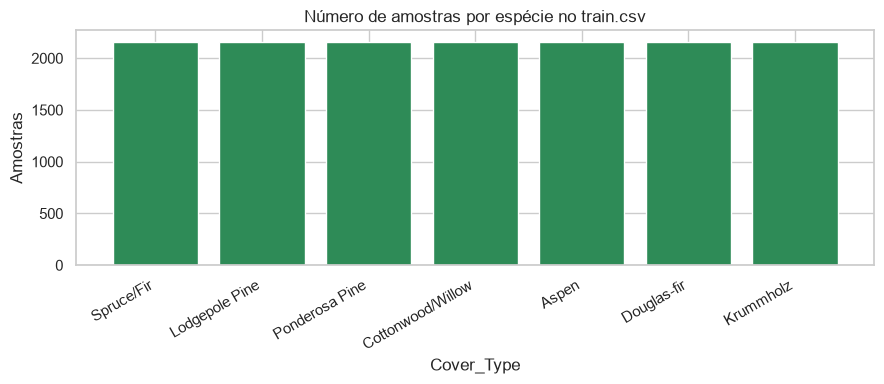

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar([COVER_NAMES[c] for c in contagem_classes.index], contagem_classes.values, color="seagreen")
ax.set_title("Número de amostras por espécie no train.csv")
ax.set_xlabel("Cover_Type")
ax.set_ylabel("Amostras")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

As 7 classes têm exatamente 2.160 amostras cada (1/7 ≈ 14,3% do total). Com isso:

- **A acurácia é uma métrica adequada**, e é a métrica oficial da competição. Acompanho também o F1 macro, que dá o mesmo peso a todas as classes e ajuda a identificar espécies com desempenho ruim.
- **O baseline é cerca de 14,3%**: um classificador que sempre chuta a mesma classe acerta 1/7 das vezes. Qualquer modelo útil precisa superar isso com folga (seção 6).
- **Não preciso de técnicas de rebalanceamento** (oversampling, pesos por classe).

Um cuidado importante: esse equilíbrio é artificial. O `train.csv` do Kaggle foi montado como uma amostra estratificada com o mesmo número de áreas por classe, mas o `test.csv` segue a distribuição real da floresta, em que Spruce/Fir e Lodgepole Pine predominam e Cottonwood/Willow é rara. Volto a esse ponto na interpretação dos resultados (seção 7).

### 2.7 Resumo da exploração inicial

| Verificação | Resultado | Consequência |
|---|---|---|
| Tipos | 56 colunas inteiras, 44 binárias one-hot | Nenhuma conversão necessária |
| Escalas | Numéricas com ordens de grandeza diferentes | Padronizar para KNN e regressão logística (3.4) |
| Valores suspeitos | Negativos em distância vertical (válidos); 88 zeros em `Hillshade_3pm` | Investigar zeros na seção 4 |
| Colunas constantes | `Soil_Type7` e `Soil_Type15` | Remover na seção 3.2 |
| Faltantes | Nenhum | `SimpleImputer` no `Pipeline` por robustez (3.1) |
| Duplicatas | Nenhuma | Nenhuma ação |
| Classes | Perfeitamente balanceadas (2.160 cada) | Acurácia como métrica principal, baseline de 14,3% |

## 3. Preparação dos dados

A preparação segue uma regra: tudo o que é **aprendido a partir dos dados** (medianas do imputador, médias e desvios da padronização) é ajustado apenas na parte de treino, dentro de um `Pipeline` do scikit-learn. Assim, na validação cruzada cada fold ajusta o pré-processamento só com os seus dados de treino, e o conjunto de teste guardado nunca influencia nenhuma decisão. Isso evita vazamento de dados (*data leakage*), que deixaria as métricas otimistas demais.

Já as decisões que não dependem dos valores aprendidos, como remover o `Id` e as colunas constantes, faço uma única vez antes da divisão.

### 3.1 Tratamento de dados faltantes

A seção 2.4 mostrou que não há nenhum valor faltante, nem no treino nem no teste do Kaggle. Mesmo assim, incluo um `SimpleImputer` no pipeline, por três motivos:

1. **Robustez em produção.** Um modelo implantado recebe dados novos, que podem vir com falhas (um cálculo de distância que não foi feito, um valor de sombreamento perdido). Sem imputador, o pipeline quebraria com um erro na primeira linha incompleta.
2. **Custo zero quando não há faltantes.** Sem valores nulos, o imputador devolve os dados exatamente como recebeu, então não altera nenhum resultado deste notebook.
3. **Sem vazamento.** Por estar dentro do `Pipeline`, os valores de preenchimento são calculados apenas com os dados de treino.

As estratégias escolhidas:

- **Numéricas: mediana.** As distâncias têm cauda longa à direita (assimetria acima de 1,2, seção 2.2). A média seria puxada pelos valores extremos; a mediana representa melhor um valor típico.
- **Binárias: valor mais frequente.** Mantém a coluna com valores 0 ou 1. Uma média produziria valores fracionários sem significado para uma variável indicadora.

Os 88 zeros de `Hillshade_3pm` não são tratados como faltantes por enquanto. Decido isso na seção 4, depois de olhar os dados com mais cuidado.

### 3.2 Remoção de colunas sem informação

Removo dois tipos de coluna:

- **`Id`:** é um número sequencial atribuído a cada linha. Não descreve o terreno, e um modelo que o usasse estaria aprendendo a ordem do arquivo, não a vegetação.
- **Colunas constantes:** uma coluna com o mesmo valor em todas as linhas não ajuda a separar nenhuma classe.

Procuro as colunas constantes por código, em vez de confiar na lista vista na seção 2.3.

In [12]:
# Colunas com um único valor em todo o train.csv
CONST_COLS = [col for col in df.columns if df[col].nunique() == 1]
print("Colunas constantes:", CONST_COLS)

# Quantas linhas do teste do Kaggle têm esses tipos de solo
if df_test_kaggle is not None:
    for col in CONST_COLS:
        n = df_test_kaggle[col].sum()
        print(f"{col} no teste do Kaggle: {n} linhas ({n / len(df_test_kaggle):.3%})")

Colunas constantes: ['Soil_Type7', 'Soil_Type15']
Soil_Type7 no teste do Kaggle: 105 linhas (0.019%)
Soil_Type15 no teste do Kaggle: 3 linhas (0.001%)


`Soil_Type7` e `Soil_Type15` valem zero em todas as linhas do treino, mas aparecem no teste do Kaggle (105 e 3 linhas, juntas cerca de 0,02% do teste). Removê-las não faz o modelo perder nada: como ele nunca viu um exemplo com esses solos, não teria como aprender o que eles significam. Nas linhas do teste com esses solos, todas as colunas de solo restantes ficam zeradas e o modelo decide pelas outras features (elevação, distâncias, área selvagem). Como são pouquíssimas linhas, o efeito na nota final é desprezível.

Os solos raros mas presentes (como `Soil_Type8` e `Soil_Type25`, com uma ocorrência cada) ficam. Eles não são constantes, e os modelos de árvore simplesmente ignoram colunas que não ajudam a dividir os dados.

Monto a matriz de features `X` e o alvo `y`. O `df_test_kaggle` fica intacto, com o `Id`, que é necessário para a submissão. As mesmas colunas são removidas dele na seção 7.

In [13]:
COLS_REMOVIDAS = ["Id"] + CONST_COLS

X = df.drop(columns=COLS_REMOVIDAS + [TARGET])
y = df[TARGET]

# Listas de colunas atualizadas, sem as constantes
BIN_COLS = [col for col in WILD_COLS + SOIL_COLS if col not in CONST_COLS]

print(f"X: {X.shape[0]} linhas x {X.shape[1]} colunas ({len(NUM_COLS)} numéricas + {len(BIN_COLS)} binárias)")

X: 15120 linhas x 52 colunas (10 numéricas + 42 binárias)


### 3.3 Divisão em treino e teste

Separo o `train.csv` em duas partes:

- **80% para treino (12.096 linhas):** usados na exploração visual (seção 4), na engenharia de features (seção 5) e na comparação de modelos com validação cruzada (seção 6).
- **20% para teste (3.024 linhas):** ficam guardados e só são usados **uma vez**, na avaliação final (seção 7). Se eu consultasse esse conjunto durante as escolhas, ele deixaria de ser uma estimativa honesta do desempenho em dados novos.

Uso `stratify=y` para que as duas partes mantenham a mesma proporção de classes do conjunto original, e `random_state=RANDOM_STATE` para que a divisão seja sempre a mesma.

Não reservo um terceiro conjunto fixo de validação. Em vez disso, uso validação cruzada estratificada com 5 folds dentro dos 80% de treino: cada linha serve de validação uma vez, aproveito melhor os dados e ainda obtenho o desvio padrão das métricas, que mostra a estabilidade de cada modelo.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Treino: {X_train.shape[0]} linhas | Teste guardado: {X_test.shape[0]} linhas")

Treino: 12096 linhas | Teste guardado: 3024 linhas


In [15]:
# Confere a estratificação: as duas partes devem ter as mesmas proporções por classe
proporcoes = pd.DataFrame({
    "espécie": [COVER_NAMES[c] for c in sorted(COVER_NAMES)],
    "treino": y_train.value_counts().sort_index().values,
    "teste": y_test.value_counts().sort_index().values,
}, index=sorted(COVER_NAMES))
proporcoes["treino (%)"] = (proporcoes["treino"] / len(y_train) * 100).round(2)
proporcoes["teste (%)"] = (proporcoes["teste"] / len(y_test) * 100).round(2)
proporcoes

,espécie,treino,teste,treino (%),teste (%)
1,Spruce/Fir,1728,432,14.29,14.29
2,Lodgepole Pine,1728,432,14.29,14.29
3,Ponderosa Pine,1728,432,14.29,14.29
4,Cottonwood/Willow,1728,432,14.29,14.29
5,Aspen,1728,432,14.29,14.29
6,Douglas-fir,1728,432,14.29,14.29
7,Krummholz,1728,432,14.29,14.29


In [16]:
# Depois da divisão, nenhuma coluna pode ter ficado constante no treino
const_no_treino = [col for col in X_train.columns if X_train[col].nunique() == 1]
print("Colunas constantes em X_train:", const_no_treino or "nenhuma")

Colunas constantes em X_train: nenhuma


A estratificação funcionou: cada classe tem 1.728 linhas no treino e 432 no teste, exatamente 14,29% em ambos. A divisão também não criou novas colunas constantes no treino, então a remoção feita antes da divisão é a mesma que eu faria olhando só os 80% de treino.

Defino aqui o esquema de validação cruzada usado em todo o resto do notebook. O `shuffle=True` embaralha as linhas antes de formar os folds, com semente fixa para reprodutibilidade.

In [17]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def avaliar_cv(modelo, X, y, n_jobs=-1):
    """Validação cruzada com CV; devolve média e desvio da acurácia e do F1 macro."""
    res = cross_validate(modelo, X, y, cv=CV, scoring=["accuracy", "f1_macro"], n_jobs=n_jobs)
    return {
        "acurácia": res["test_accuracy"].mean(),
        "acurácia (dp)": res["test_accuracy"].std(),
        "F1 macro": res["test_f1_macro"].mean(),
        "F1 macro (dp)": res["test_f1_macro"].std(),
    }

### 3.4 Normalização/Padronização

A seção 2.2 mostrou escalas muito diferentes: as distâncias horizontais têm desvio padrão acima de 1.000 m, enquanto `Slope` tem desvio de 8,5 graus. Uso a padronização (`StandardScaler`), que subtrai a média e divide pelo desvio padrão de cada variável: z = (x − μ) / σ. Depois dela, todas as numéricas ficam com média 0 e desvio 1. Prefiro padronizar a normalizar para o intervalo [0, 1] (`MinMaxScaler`) porque a normalização depende do mínimo e do máximo, que são justamente os valores extremos das distâncias com cauda longa.

**Quem precisa de padronização e por quê:**

- **KNN:** classifica pela distância euclidiana entre pontos. Sem padronização, uma diferença de 1.000 m na distância até a estrada pesa milhares de vezes mais que uma diferença de 1 grau na inclinação. Na prática, o modelo passa a usar só as variáveis com números grandes, e quem decide o peso de cada variável é a unidade de medida, não a sua importância.
- **Regressão logística:** é ajustada por um otimizador numérico (`lbfgs`) que converge mal quando as variáveis estão em escalas muito diferentes. Além disso, a regularização L2 penaliza o tamanho dos coeficientes. Sem padronização, a penalidade atinge as variáveis de forma desigual, só por causa das suas unidades.
- **Modelos de árvore (Random Forest, Extra Trees, Gradient Boosting):** não precisam. Cada divisão de uma árvore compara uma única variável com um limiar (por exemplo, `Elevation <= 2.900`). Padronizar só muda o valor do limiar, não a ordem dos pontos, então as divisões possíveis são as mesmas.

**Quem é padronizado:** apenas as 10 numéricas. As binárias passam sem alteração (só pelo imputador), porque 0 e 1 já são uma escala pequena e interpretável (ausência ou presença) e padronizá-las não acrescentaria informação.

Monto o pré-processamento como uma função, para reutilizá-lo nas próximas seções com outras listas de colunas (por exemplo, com as features criadas na seção 5).

In [18]:
def build_preprocessor(num_cols, bin_cols, padronizar=True):
    """Imputação + (opcionalmente) padronização nas numéricas; binárias só passam pelo imputador."""
    passos_num = [("imputer", SimpleImputer(strategy="median"))]
    if padronizar:
        passos_num.append(("scaler", StandardScaler()))

    return ColumnTransformer(
        [
            ("num", Pipeline(passos_num), num_cols),
            ("bin", SimpleImputer(strategy="most_frequent"), bin_cols),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

Para mostrar que o pré-processador aprende só com o treino, ajusto-o em `X_train` e transformo as duas partes. No treino, as numéricas devem ficar com média 0 e desvio 1 exatamente. No teste, os valores ficam próximos, mas não exatos, porque são transformados com a média e o desvio **do treino**. É assim que o modelo vai receber dados novos.

In [19]:
preprocessor = build_preprocessor(NUM_COLS, BIN_COLS)
Xt_train = preprocessor.fit_transform(X_train)
Xt_test = preprocessor.transform(X_test)

pd.DataFrame({
    "média (treino)": Xt_train[NUM_COLS].mean(),
    "desvio (treino)": Xt_train[NUM_COLS].std(ddof=0),
    "média (teste)": Xt_test[NUM_COLS].mean(),
    "desvio (teste)": Xt_test[NUM_COLS].std(ddof=0),
}).round(3)

,média (treino),desvio (treino),média (teste),desvio (teste)
Elevation,0.0,1.0,-0.008,0.996
Aspect,0.0,1.0,0.016,1.013
Slope,0.0,1.0,0.000,0.992
Horizontal_Distance_To_Hydrology,0.0,1.0,0.012,1.002
Vertical_Distance_To_Hydrology,-0.0,1.0,-0.004,0.974
Horizontal_Distance_To_Roadways,-0.0,1.0,-0.018,1.010
Hillshade_9am,0.0,1.0,-0.016,0.991
Hillshade_Noon,0.0,1.0,-0.006,0.998
Hillshade_3pm,-0.0,1.0,0.010,0.994
Horizontal_Distance_To_Fire_Points,0.0,1.0,-0.018,0.939


Também testo o imputador: copio duas linhas do teste, apago alguns valores e passo pelo pré-processador já ajustado. As lacunas numéricas devem ser preenchidas com a mediana do treino (que, depois de padronizada, aparece como um valor próximo de zero) e as binárias com o valor mais frequente.

In [20]:
amostra = X_test.head(2).copy().astype(float)
amostra.loc[amostra.index[0], "Elevation"] = np.nan
amostra.loc[amostra.index[1], ["Hillshade_3pm", "Wilderness_Area3"]] = np.nan

print("Faltantes antes:", amostra.isnull().sum().sum())
transformada = preprocessor.transform(amostra)
print("Faltantes depois:", transformada.isnull().sum().sum())
print("Mediana de Elevation no treino:", X_train["Elevation"].median())
transformada[["Elevation", "Hillshade_3pm", "Wilderness_Area3"]].round(3)

Faltantes antes: 3
Faltantes depois: 0


Mediana de Elevation no treino: 2753.0


,Elevation,Hillshade_3pm,Wilderness_Area3
3551,0.007,-1.654,0.0
5928,-1.041,0.065,0.0


O pré-processador funciona como esperado: média 0 e desvio 1 no treino, valores próximos no teste, e nenhuma lacuna depois da imputação.

Agora verifico na prática se a padronização faz diferença para cada tipo de modelo. Comparo regressão logística, KNN e Random Forest com e sem padronização, sempre com validação cruzada nos 80% de treino. Os três modelos ficam com os hiperparâmetros padrão; o objetivo aqui não é escolher o melhor modelo (isso é a seção 6), e sim isolar o efeito da padronização.

Antes, mostro o problema de convergência da regressão logística. O atributo `n_iter_` informa quantas iterações o otimizador usou; se for igual ao limite `max_iter`, ele parou sem convergir.

In [21]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for padronizar in [False, True]:
        logreg = Pipeline([
            ("prep", build_preprocessor(NUM_COLS, BIN_COLS, padronizar=padronizar)),
            ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        ]).fit(X_train, y_train)
        n_iter = logreg.named_steps["model"].n_iter_[0]
        print(f"Padronizado: {padronizar!s:5} | iterações usadas: {n_iter} de 1000")

Padronizado: False | iterações usadas: 1000 de 1000
Padronizado: True  | iterações usadas: 153 de 1000


In [22]:
modelos = {
    "Regressão logística": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN (k=5)": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}

resultados = []
# n_jobs=1 para que os avisos de convergência do caso sem padronização fiquem silenciados aqui
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for nome, modelo in modelos.items():
        for padronizar in [False, True]:
            pipe = Pipeline([
                ("prep", build_preprocessor(NUM_COLS, BIN_COLS, padronizar=padronizar)),
                ("model", modelo),
            ])
            metricas = avaliar_cv(pipe, X_train, y_train, n_jobs=1)
            resultados.append({"modelo": nome, "padronização": "sim" if padronizar else "não", **metricas})

pd.DataFrame(resultados).set_index(["modelo", "padronização"]).round(4)

acurácia  acurácia (dp)  F1 macro  \
modelo              padronização                                      
Regressão logística não             0.6084         0.0094    0.6009   
                    sim             0.7049         0.0079    0.7017   
KNN (k=5)           não             0.7892         0.0065    0.7815   
                    sim             0.7736         0.0066    0.7688   
Random Forest       não             0.8545         0.0032    0.8524   
                    sim             0.8539         0.0041    0.8517   

                                  F1 macro (dp)  
modelo              padronização                 
Regressão logística não                  0.0100  
                    sim                  0.0083  
KNN (k=5)           não                  0.0070  
                    sim                  0.0069  
Random Forest       não                  0.0034  
                    sim                  0.0043

**Interpretação:**

- **Regressão logística: a padronização é indispensável.** Sem ela, o otimizador esgota as 1.000 iterações sem convergir e a acurácia fica por volta de 61%. Com ela, converge em 153 iterações e chega a cerca de 70%. É o comportamento esperado pela teoria.
- **Random Forest: a padronização não muda nada.** A diferença de acurácia é de 0,0006 (85,45% contra 85,39%), bem abaixo do desvio entre os folds (cerca de 0,004). Isso confirma que as árvores são insensíveis à escala. A pequena variação vem apenas de arredondamentos em ponto flutuante, que às vezes desempatam limiares de forma diferente.
- **KNN: o resultado contraria a intuição.** O KNN sem padronização acerta um pouco mais (cerca de 79% contra 77%). Isso não quer dizer que a escala original seja melhor em geral. Sem padronização, a distância euclidiana fica dominada pelas distâncias horizontais até estradas e pontos de ignição (desvio acima de 1.000 m) e pela elevação, e as demais variáveis quase não contam. Acontece que essas variáveis de escala grande são justamente das mais informativas neste problema. Minha hipótese é que as distâncias até estradas e pontos de ignição funcionam quase como coordenadas geográficas: pontos com valores parecidos tendem a estar próximos no terreno e a ter a mesma vegetação. Verifico isso na análise de features (seções 4 e 5).

**Decisão:** mantenho o `StandardScaler` como padrão no pipeline de todos os modelos. Para a regressão logística ele é necessário, e para as árvores é indiferente. Para o KNN, o peso que a escala original dá a cada variável é um acidente das unidades de medida (metros contra graus), não uma escolha justificada. Por isso, em vez de simplesmente abrir mão da padronização, trato-a como um hiperparâmetro do KNN na seção 6 (`StandardScaler` ou nenhum) e deixo a validação cruzada decidir.

### 3.5 Resumo da preparação

| Etapa | Decisão | Onde é ajustada |
|---|---|---|
| Faltantes | `SimpleImputer`: mediana nas numéricas, mais frequente nas binárias | Dentro do `Pipeline` (só treino) |
| Colunas removidas | `Id`, `Soil_Type7`, `Soil_Type15` | Antes da divisão (não depende de valores aprendidos) |
| Divisão | 80/20 estratificada, `random_state=42`; teste guardado até a seção 7 | |
| Validação | `StratifiedKFold(5)` nos 80% de treino, acurácia e F1 macro | |
| Escala | `StandardScaler` nas 10 numéricas; binárias sem alteração | Dentro do `Pipeline` (só treino) |

## 4. Exploração e visualização dos dados

> TODO: gráficos com uma conclusão escrita abaixo de cada um.

Sugestões:
- [ ] Histogramas das variáveis numéricas
- [ ] Boxplots de cada numérica por classe (a elevação deve separar bem as espécies)
- [ ] Mapa de calor de correlação das numéricas
- [ ] Frequência das áreas selvagens e dos tipos de solo por classe
- [ ] Outliers: `Vertical_Distance_To_Hydrology` negativo é válido? `Hillshade_3pm` tem zeros suspeitos?

In [23]:
# TODO: visualizações (usar apenas o conjunto de treino)

## 5. Engenharia e seleção de features

> TODO: criar, justificar e medir o ganho de cada feature com validação cruzada.

Ideias:
- [ ] `Aspect` em seno e cosseno (variável circular: 0° e 360° são a mesma direção)
- [ ] Distância em linha reta até a água: √(H² + V²)
- [ ] Altitude estimada da água: `Elevation - Vertical_Distance_To_Hydrology`
- [ ] Somas e diferenças entre distâncias (água, estradas, pontos de fogo)
- [ ] Comparar o desempenho com e sem as features novas

In [24]:
# TODO: transformações de features (de preferência como função ou transformer reutilizável)

## 6. Modelagem, comparação e validação cruzada

> TODO: comparar modelos com `StratifiedKFold(5)` medindo acurácia e F1 macro (média e desvio padrão).

Modelos sugeridos:
- [ ] `DummyClassifier` (baseline: cerca de 1/7 de acerto)
- [ ] Regressão logística
- [ ] KNN
- [ ] Random Forest ou Extra Trees
- [ ] `HistGradientBoostingClassifier`
- [ ] Ajuste de hiperparâmetros só no melhor modelo (`GridSearchCV` ou `RandomizedSearchCV`)

In [25]:
# TODO: pipelines, validação cruzada e tabela comparativa

## 7. Avaliação dos resultados

> TODO: avaliar o modelo final uma única vez nos 20% guardados.

- [ ] Matriz de confusão 7×7
- [ ] `classification_report` (precisão, recall e F1 por classe)
- [ ] Curvas ROC um-contra-todos
- [ ] Importância das features por permutação
- [ ] Interpretação: quais espécies se confundem e por quê
- [ ] Submissão ao Kaggle (late submission) e nota obtida

In [26]:
# TODO: avaliação final e geração do arquivo de submissão

## 8. Conclusão e próximos passos

> TODO: resumir os principais achados e sugerir melhorias.

### Resumo dos achados

### Próximos passos

## 9. Reprodutibilidade

- Versões das bibliotecas: `requirements.txt`
- Semente aleatória: `RANDOM_STATE = 42`
- Dados: baixados do Kaggle conforme o README
- Para reproduzir: `Kernel → Restart & Run All`